# TA-05: Implementasi Simulasi Kejadian Diskrit Bengkel dengan Python

Notebook ini menerjemahkan model bengkel (2 montir) dari JaamSim ke kode Python, dengan **mesin DES dari nol** (tanpa library simulasi).

| Komponen DES | Implementasi Python |
|---|---|
| Entitas | mobil (nomor urut) |
| Antrian | `deque` (FIFO): `qd`, `qt`, `qb` |
| Sumber daya | status `free[...]` untuk pendaftaran, 2 montir, pembayaran |
| Event calendar | `heapq` (priority queue berurutan waktu) |
| Simulation clock | variabel `t` yang melompat ke kejadian berikutnya |

Alur: Kedatangan, Antrian-Daftar, Pendaftaran, Ruang-Tunggu, Montir 1 / Montir 2, Antrian-Bayar, Pembayaran, Keluar.

In [1]:
# 1. Mesin simulasi
import heapq, random, itertools
from collections import deque

# Parameter model (menit) - sama dengan model JaamSim
P = dict(mean_iat=20, daftar=(2, 4), repair=(20, 30, 40), bayar=(2, 4), T=480)

def simulate(seed=42, log=False, **kw):
    """Mesin DES sederhana: simulation clock + event calendar + antrian."""
    p = {**P, **kw}; T = p['T']
    rng = random.Random(seed)
    cal, seq = [], itertools.count()            # event calendar (priority queue)
    qd, qt, qb = deque(), deque(), deque()      # Antrian-Daftar, Ruang-Tunggu, Antrian-Bayar
    free = {'daftar': True, 'm1': True, 'm2': True, 'bayar': True}
    busy = dict.fromkeys(free, 0.0)             # total waktu sibuk tiap server
    waits, events = [], []
    area = last = 0.0; arrived = done = lmax = 0

    def sched(t, kind, data=None):
        heapq.heappush(cal, (t, next(seq), kind, data))
    def serve(name, now, dur):
        free[name] = False; busy[name] += min(dur, T - now)
    def try_daftar(now):
        if free['daftar'] and qd:
            car, _ = qd.popleft(); d = rng.uniform(*p['daftar'])
            serve('daftar', now, d); sched(now + d, 'END_DAFTAR', car)
    def try_montir(now):
        for m in ('m1', 'm2'):                  # Montir 1 dicek lebih dulu
            if free[m] and qt:
                car, t0 = qt.popleft(); waits.append(now - t0)
                lo, mode, hi = p['repair']; d = rng.triangular(lo, hi, mode)
                serve(m, now, d); sched(now + d, 'END_REPAIR', (car, m))
    def try_bayar(now):
        if free['bayar'] and qb:
            car, _ = qb.popleft(); d = rng.uniform(*p['bayar'])
            serve('bayar', now, d); sched(now + d, 'END_BAYAR', car)

    sched(0.0, 'ARRIVE')                        # kedatangan pertama pada t = 0
    while cal:                                  # loop utama
        t, _, kind, data = heapq.heappop(cal)   # ambil kejadian terdekat
        if t > T: break
        area += len(qt) * (t - last); last = t  # lompatkan clock ke t
        if kind == 'ARRIVE':
            arrived += 1; car = arrived; qd.append((car, t))
            sched(t + rng.expovariate(1 / p['mean_iat']), 'ARRIVE')
            try_daftar(t)
        elif kind == 'END_DAFTAR':
            car = data; free['daftar'] = True; qt.append((car, t))
            try_daftar(t); try_montir(t)
        elif kind == 'END_REPAIR':
            car, m = data; free[m] = True; qb.append((car, t))
            try_montir(t); try_bayar(t)
        else:
            car = data; free['bayar'] = True; done += 1; try_bayar(t)
        lmax = max(lmax, len(qt))
        if log: events.append((round(t, 2), kind, car))
    area += len(qt) * (T - last)
    res = dict(datang=arrived, selesai=done,
               util_montir1=busy['m1'] / T, util_montir2=busy['m2'] / T,
               util_daftar=busy['daftar'] / T, util_bayar=busy['bayar'] / T,
               tunggu_rata_menit=sum(waits) / len(waits) if waits else 0.0,
               antrian_rata=area / T, antrian_maks=lmax)
    return (res, events) if log else res


## 2. Satu kali simulasi (seed 42) dan log kejadian awal

In [2]:
import pandas as pd
res, ev = simulate(seed=42, log=True)
print(pd.Series(res).round(4).to_string())
print()
print(pd.DataFrame(ev[:12], columns=["menit", "kejadian", "mobil"]).to_string(index=False))

datang               23.0000
selesai              23.0000
util_montir1          0.7484
util_montir2          0.6646
util_daftar           0.1443
util_bayar            0.1355
tunggu_rata_menit     9.6658
antrian_rata          0.4632
antrian_maks          4.0000

 menit   kejadian  mobil
  0.00     ARRIVE      1
  2.05 END_DAFTAR      1
 20.40     ARRIVE      2
 23.87 END_DAFTAR      2
 25.45     ARRIVE      3
 27.63 END_DAFTAR      3
 29.47 END_REPAIR      1
 31.53  END_BAYAR      1
 55.83 END_REPAIR      2
 58.27  END_BAYAR      2
 58.65 END_REPAIR      3
 61.66  END_BAYAR      3


## 3. Replikasi 30 kali dan perbandingan dengan JaamSim

Karena kedatangan dan waktu layanan acak, satu run belum cukup. Hasil JaamSim di bawah adalah 1 run.

In [3]:
# Hasil JaamSim (1 run, 8 jam) untuk pembanding
jaamsim = dict(datang=18, selesai=17, util_montir1=0.6785, util_montir2=0.4585,
               util_daftar=0.1106, util_bayar=0.1109, tunggu_rata_menit=5.24,
               antrian_rata=0.1967, antrian_maks=2)

runs = pd.DataFrame([simulate(seed=s) for s in range(100, 130)])
tabel = pd.DataFrame({"Python (rata-rata 30 run)": runs.mean(),
                      "Std. deviasi": runs.std(),
                      "JaamSim (1 run)": pd.Series(jaamsim)}).round(4)
tabel

,Python (rata-rata 30 run),Std. deviasi,JaamSim (1 run)
datang,24.3000,4.2923,18.0000
selesai,21.8333,3.5631,17.0000
util_montir1,0.7768,0.1038,0.6785
util_montir2,0.6388,0.1472,0.4585
util_daftar,0.1514,0.0256,0.1106
util_bayar,0.1358,0.0218,0.1109
tunggu_rata_menit,11.8395,11.0542,5.2400
antrian_rata,0.6452,0.6876,0.1967
antrian_maks,3.3333,1.9535,2.0000


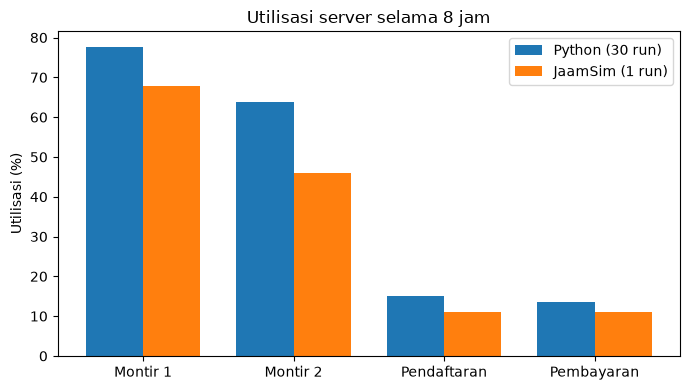

In [4]:
import matplotlib.pyplot as plt
k = ["util_montir1", "util_montir2", "util_daftar", "util_bayar"]
nama = ["Montir 1", "Montir 2", "Pendaftaran", "Pembayaran"]
x = range(len(k)); w = 0.38
plt.figure(figsize=(7, 4))
plt.bar([i - w/2 for i in x], [runs[c].mean() * 100 for c in k], w, label="Python (30 run)")
plt.bar([i + w/2 for i in x], [jaamsim[c] * 100 for c in k], w, label="JaamSim (1 run)")
plt.xticks(list(x), nama); plt.ylabel("Utilisasi (%)"); plt.title("Utilisasi server selama 8 jam")
plt.legend(); plt.tight_layout(); plt.show()

## 4. Analisis dan kesimpulan

- Perkiraan teoretis: utilisasi montir sekitar 30 / (2 x 20) = 75%, pendaftaran dan pembayaran sekitar 3 / 20 = 15%, dan sekitar 24 mobil datang dalam 8 jam.
- Bandingkan rata-rata 30 run dengan perkiraan itu dan dengan hasil JaamSim (1 run). Satu run JaamSim kebetulan hanya memiliki 18 kedatangan, lebih sedikit dari rata-rata sekitar 24 (std. deviasi sekitar 4), sehingga utilisasi dan antriannya lebih rendah. Selisih seperti ini wajar pada proses acak.
- Tuliskan kesimpulan: apakah 2 montir cukup (lihat `antrian_rata`, `antrian_maks`, `tunggu_rata_menit`).

**Keterbatasan:** pendaftaran dan pembayaran dimodelkan sebagai dua server terpisah (di soal dilayani resepsionis yang sama), dan generator angka acak Python berbeda dari JaamSim sehingga hasil hanya sebanding secara statistik.